<a href="https://colab.research.google.com/github/scaba3-wq/CS418/blob/HW-2/hw2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 2: Exploratory data analysis and visualization

UIC CS 418, Fall 2026

**Academic Integrity Policy**: According to the Academic Integrity Policy of this course, all work submitted for grading must be done individually, unless otherwise specified. While we encourage you to talk to your peers and learn from them, this interaction must be superficial with regards to all work submitted for grading. This means you cannot work in teams, you cannot work side-by-side, you cannot submit someone else’s work (partial or complete) as your own. In particular, note that you are guilty of academic dishonesty if you extend or receive any kind of unauthorized assistance. Absolutely no transfer of program code between students is permitted (paper or electronic), and you may not solicit code from family, friends, or online forums. Other examples of academic dishonesty include emailing your program to another student, copying-pasting code from the internet, working in a group on a homework assignment, and allowing a tutor, TA, or another individual to write an answer for you. Academic dishonesty is unacceptable, and penalties range from failure to expulsion from the university; cases are handled via the official student conduct process described at https://dos.uic.edu/community-standards/academic-integrity/

This homework is an individual assignment for all graduate students. Undergraduate students are allowed to work in pairs to discuss and share ideas with each other, but you still need to work and submit homework by yourself. **Identical submissions are not allowed**. The pairs of students who choose to work together still need to abide by the **Academic Integrity Policy** and not share or receive help from others (except each other).

There are three parts in this homework. The zero one is a practice introduction to `matplotlib` (5%). The first part is a guided exploration of a bikeshare dataset (40%). The second one is a self-guided exploration of a dataset on social media and internet attitudes (45%). Third part deals with understanding of loss functions (10%). You can also earn extra credit of 10%.


## Due Date

This assignment is due at 11:59pm Saturday, March 1st. Late submissions will not be considered.


## Submission Instruction

You need to complete all code and answer all questions denoted by **Q#** in this notebook. After executing all commands and completing this notebook, export/convert your *hw2.ipynb* to a **pdf** file and upload it to Gradescope under *Homework 2 (pdf)*. Make sure you check that your **pdf** file includes all parts of your solution **(including the outputs)**. Check `warmup.pdf` for an example of expected submission file. You are also reqired to submit your **.iypnb** file to the *Homework 2 (code)* section with all the output visibile in the output cells.

**Note**:
When you submit the solution to Gradescope, it is necessary that you **mark/tag all pages of each solution to its question based on the homework outline**, so that it can be easily found. You may lose marks if you don't mark your solutions.

In [ ]:
# this just shows the current directory
!pwd

/content


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# STEP1: upload the folder on your google drive
# Step2: Find the URL - it will look something like below - Now we set the working directory to the folder
%cd "/content/drive/MyDrive/CS418_Fall2026_HW2"

!pwd

# this should look like this: '/content/drive/MyDrive/CS418_Spring2025_HW1'

/content/drive/MyDrive/CS418_Fall2026_HW2
/content/drive/MyDrive/CS418_Fall2026_HW2


In [ ]:
%pip install seaborn

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
%matplotlib inline
import matplotlib.pyplot as plt

# Practice: `matplotlib` (5%)

[`matplotlib`][mpl] is the most widely used plotting library available for Python. It comes with a good amount of out-of-the-box functionality and is highly customizable. Most other plotting libraries in Python provide simpler ways to generate complicated `matplotlib` plots, including `seaborn`, so it's worth learning a bit about `matplotlib` now.

Notice how all of our notebooks have lines that look like:

	%matplotlib inline
	import matplotlib.pyplot as plt

The `%matplotlib inline` magic command tells `matplotlib` to render the plots
directly onto the notebook (by default it will open a new window with the plot).

Then, the `import` line lets us call `matplotlib` functions using `plt.<func>`

Here's a graph of `sin(x)` from 0 to 2 * pi.

[mpl]: http://matplotlib.org/

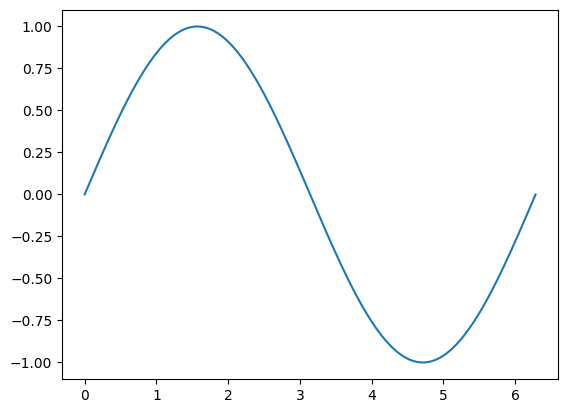

In [ ]:
# Set up (x, y) pairs from 0 to 2*pi
xs = np.linspace(0, 2 * np.pi, 300)
ys = np.sin(xs)

# plt.plot takes in x-values and y-values and plots them as a line
plt.plot(xs, ys)

`matplotlib` also conveniently has the ability to plot multiple things on the same plot. Just call `plt.plot` multiple times in the same cell:

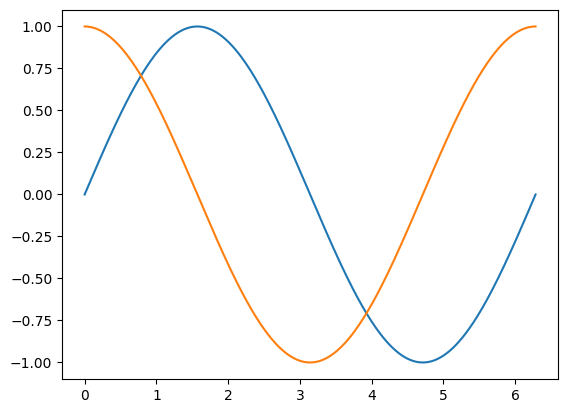

In [ ]:
plt.plot(xs, ys)
plt.plot(xs, np.cos(xs))

That plot looks pretty nice but isn't presentation-ready. Luckily, `matplotlib` has a wide array of plot customizations.


## Q0 (5%):

Skim through the first part of the tutorial at https://github.com/rougier/matplotlib-tutorial to create the plot below. There is a lot of extra information there which we suggest
you read on your own time. For now, just look for what you need to make the plot.

Specifically, you'll have to change the x and y limits, add a title, and add a legend.

![](q1.png)

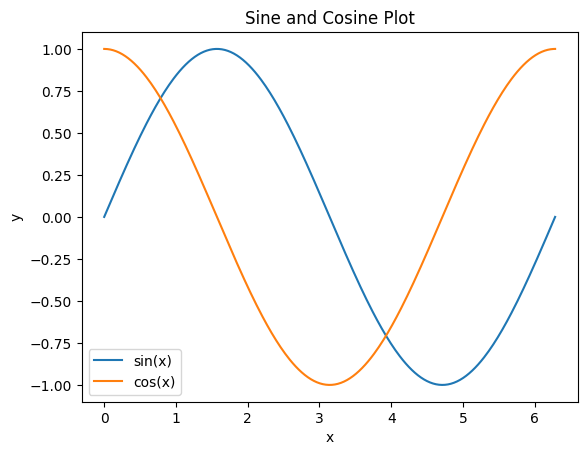

In [ ]:
# Here's the starting code from last time. Edit / Add code to create the plot above.
plt.plot(xs, ys)
plt.plot(xs, np.cos(xs))
plt.title("Sine and Cosine Plot")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(["sin(x)", "cos(x)"])
plt.show()

# Part 1: Guided EDA of bikeshare trips (40%)

You will be performing some basic EDA (exploratory data analysis) on
bikeshare data in Washington D.C.

The variables in this data frame are defined as:

- instant: record index
- dteday : date
- season : season (1:spring, 2:summer, 3:fall, 4:winter)
- yr : year (0: 2011, 1:2012)
- mnth : month ( 1 to 12)
- hr : hour (0 to 23)
- holiday : whether day is holiday or not
- weekday : day of the week (Sunday to Saturday)
- workingday : if day is neither weekend nor holiday
- weathersit :
    - 1: Clear or partly cloudy
    - 2: Mist + clouds
    - 3: Light Snow or Rain
    - 4: Heavy Rain or Snow
- temp : Normalized temperature in Celsius (divided by 41)
- atemp: Normalized feeling temperature in Celsius (divided by 50)
- hum: Normalized percent humidity (divided by 100)
- windspeed: Normalized wind speed (divided by 67)
- casual: count of casual users
- registered: count of registered users
- cnt: count of total rental bikes including casual and registered

In [ ]:
bike_trips = pd.read_csv('bikeshare.csv')

# Here we'll do some pandas datetime parsing so that the dteday column
# contains datetime objects.
bike_trips['dteday'] += ':' + bike_trips['hr'].astype(str)
bike_trips['dteday'] = pd.to_datetime(bike_trips['dteday'], format="%Y-%m-%d:%H")
bike_trips = bike_trips.drop(['yr', 'mnth', 'hr'], axis=1)

bike_trips.head()

,instant,dteday,season,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01 00:00:00,1,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01 01:00:00,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01 02:00:00,1,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01 03:00:00,1,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01 04:00:00,1,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## Q1.1 (10%):
Explore the `bike_trips` dataframe to answer the following questions.


What time range is represented here?
What was the maximum registration (use the "registered" column) on a SINGLE DAY

Write code in the cell below to perform your exploration.

In [ ]:
# your code here
range = bike_trips['dteday'].max() - bike_trips['dteday'].min()
print(range)

730 days 23:00:00


## Using `pandas` to plot

`pandas` provides useful methods on dataframes. For simple plots, we prefer to
just use those methods instead of the `matplotlib` methods since we're often
working with dataframes anyway. The syntax is:

    dataframe.plot.<plotfunc>

Where the `<plotfunc>` is one of the functions listed under _Plotting_ here: https://pandas.pydata.org/pandas-docs/stable/reference/frame.html

<Axes: xlabel='dteday'>

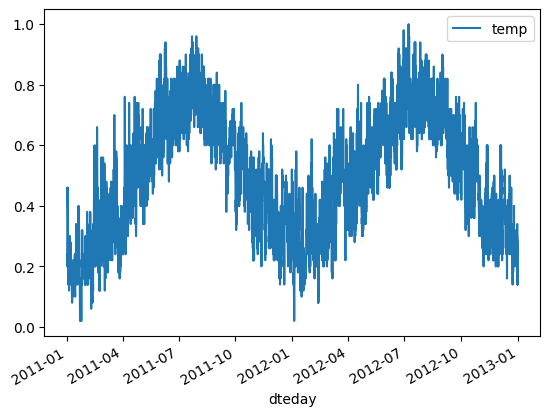

In [ ]:
# This plot shows the temperature at each data point
bike_trips.plot.line(x='dteday', y='temp')

## `seaborn`

Now, we'll learn how to use the [`seaborn`][sns] Python library. `seaborn`
is built on top of `matplotlib` and provides many helpful functions
for statistical plotting that `matplotlib` and `pandas` don't have.

Generally speaking, we'll use `seaborn` for more complex statistical plots,
`pandas` for simple plots (eg. line / scatter plots), and
`matplotlib` for plot customization.

Nearly all `seaborn` functions are designed to operate on `pandas`
dataframes. Most of these functions assume that the dataframe is in
a specific format called *long-form*, where each column of the dataframe
is a particular feature and each row of the dataframe a single datapoint.

For example, this dataframe is long-form:

```
   country year avgtemp
 1  Sweden 1994       6
 2 Denmark 1994       6
 3  Norway 1994       3
 4  Sweden 1995       5
 5 Denmark 1995       8
 6  Norway 1995      11
 7  Sweden 1996       7
 8 Denmark 1996       8
 9  Norway 1996       7
```

But this dataframe of the same data is not:

```
   country avgtemp.1994 avgtemp.1995 avgtemp.1996
 1  Sweden            6            5            7
 2 Denmark            6            8            8
 3  Norway            3           11            7
```

Note that the `bike_trips` dataframe is long-form.

For more about long-form data, see https://stanford.edu/~ejdemyr/r-tutorials/wide-and-long.
For now, just remember that we typically prefer long-form data and it makes plotting using
`seaborn` easy as well.

[sns]: http://seaborn.pydata.org/index.html

We can create the same plot as the `dataframe.plot` above using the following `seaborn` function: `sns.lineplot`. Notice that instead of calling the plot function on dataframe object, here we pass it as a parameter to the function:

Text(0.5, 1.0, 'Temperature Changes from 2011 to 2013')

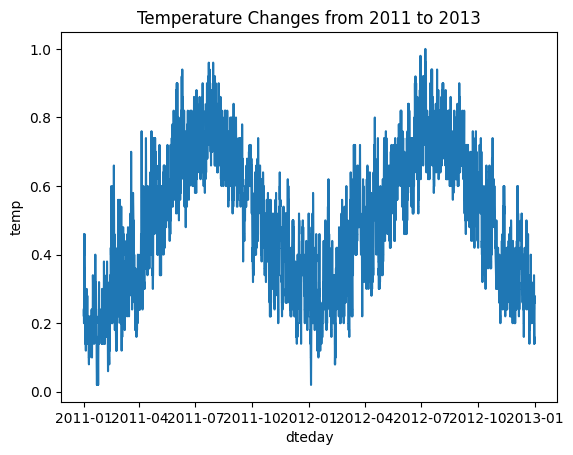

In [ ]:
# You can create a plot similar to the one above using the following seaborn syntax
# Note that the seaborn plot is a bit different and requires some customizations (more on this later)
sns.lineplot(x="dteday", y="temp", data=bike_trips)
plt.title("Temperature Changes from 2011 to 2013")

## Q1.2 (10%):

Use seaborn's `barplot` function to make a bar chart showing
1. the average number of registered riders on each day of the week over the
   entire `bike_trips` dataset.
2. the average number of casual riders on each day of the week over the
   entire `bike_trips` dataset.

Here's a link to the seaborn API: http://seaborn.pydata.org/api.html
.

What trends do you notice? What do you suppose causes these trends?

Notice that `barplot` draws error bars for each category. It uses bootstrapping to make those.

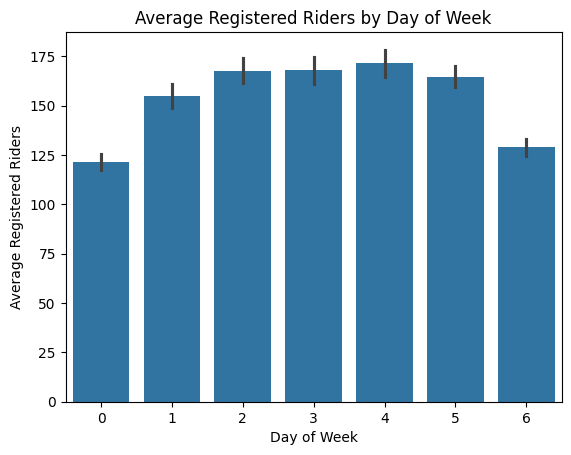

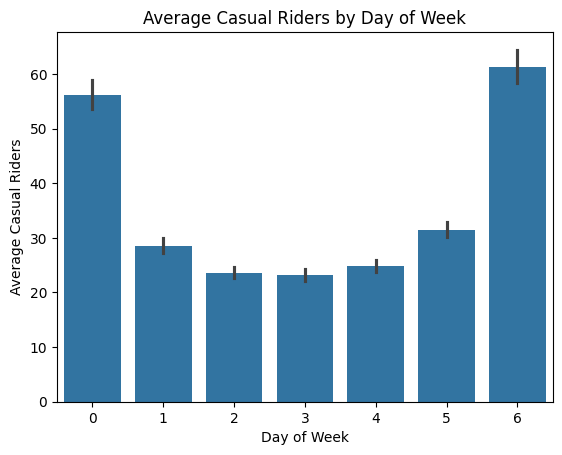

In [ ]:
# your code here
sns.barplot(x="weekday", y="registered", data=bike_trips)

plt.title("Average Registered Riders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Registered Riders")
plt.show()

sns.barplot(x="weekday", y="casual", data=bike_trips)

plt.title("Average Casual Riders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Casual Riders")
plt.show()

# 0 = Monday, 1 = Tuesday, 2 = Wednesday, ...

(Your Q1.2 answer here)


## Q1.3 (10%):

Use `seaborn` to make side-by-side boxplots of the number of casual riders (just
checked out a bike for that day) and registered riders (have a bikeshare membership). The `boxplot` function will plot all the columns of the dataframe you pass in.

Once you make the plot, you'll notice that there are many outliers that make the plot hard to see. To mitigate this, change the y-scale to be logarithmic.

That's a plot customization so you'll use `matplotlib`. The `boxplot` function returns a `matplotlib` Axes object which represents a single plot and has a `set_yscale` function.

The result (after customization) should look like **q5.png**.


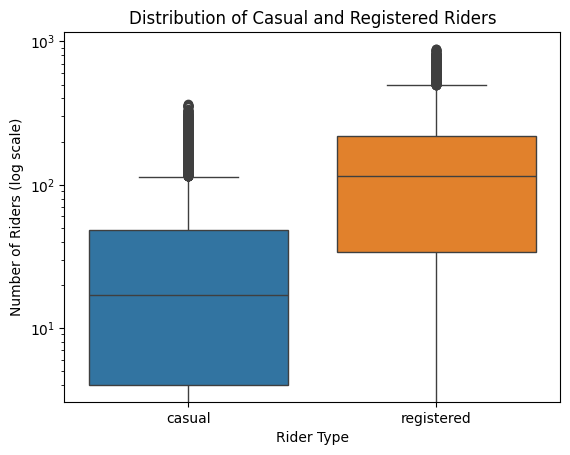

In [ ]:
# your code here
ax = sns.boxplot(
    data=bike_trips[["casual", "registered"]]
)

ax.set_yscale("log")

plt.title("Distribution of Casual and Registered Riders")
plt.xlabel("Rider Type")
plt.ylabel("Number of Riders (log scale)")

plt.show()


## Q1.4 (10%):

Let's take a closer look at the number of registered vs. casual riders.

Use the `lmplot` function to make a scatterplot. Put the number of casual
riders on the x-axis and the number of registered riders on the y-axis.
Each point should correspond to a single row in your `bike_trips` dataframe. Notice that `seaborn` automatically fits a line of best fit to the plot. Does that line seem to be relevant?

You should note that `lmplot` allows you to pass in `fit_line=False` to
avoid plotting lines of best fit when you feel they are unnecessary
or misleading.

There seem to be two main groups in the scatterplot. Let's
see if we can separate them out. Use `lmplot` to make the scatterplot again. This time, use the `hue` parameter
to color points for weekday trips differently from weekend trips. You should
get something that looks like **q1-5.png**.



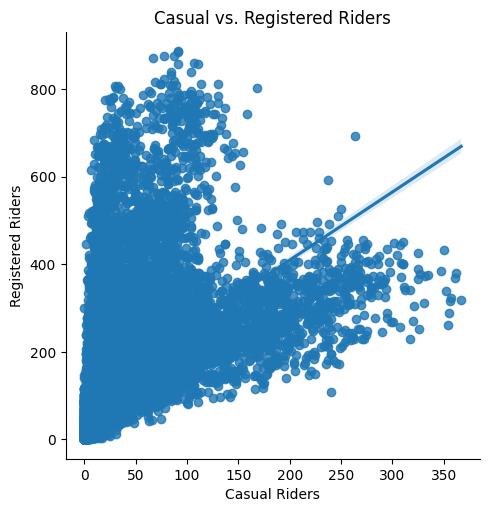

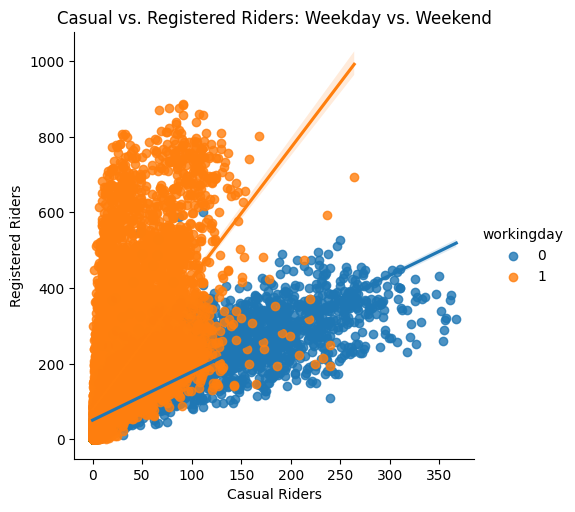

In [ ]:
# In your plot, you'll notice that your points are larger than ours. That's
# fine. If you'd like them to be smaller, you can add scatter_kws={'s': 6}
# to your lmplot call. That tells the underlying matplotlib scatter function
# to change the size of the points.

# your code here
sns.lmplot(x="casual", y="registered", data=bike_trips)
plt.title("Casual vs. Registered Riders")
plt.xlabel("Casual Riders")
plt.ylabel("Registered Riders")
plt.show()

sns.lmplot(x="casual", y="registered", data=bike_trips, hue="workingday")
plt.title("Casual vs. Registered Riders: Weekday vs. Weekend")
plt.xlabel("Casual Riders")
plt.ylabel("Registered Riders")
plt.show()

# Note that the legend for workingday isn't super helpful. 0 in this case
# means "not a working day" and 1 means "working day". Try fixing the legend
# to be more descriptive.
# HINT: ax = sns.lmplot(..., legend=True)
# legendObj = ax.legend # Modify this object

## Want to learn more?

Check out the `seaborn` tutorials on your own time. http://seaborn.pydata.org/tutorial.html

The `matplotlib` tutorial we linked in Question 1 is also a great refresher on common `matplotlib` functions: https://www.labri.fr/perso/nrougier/teaching/matplotlib/

The differences between Python's visualization libraries:
https://dansaber.wordpress.com/2016/10/02/a-dramatic-tour-through-pythons-data-visualization-landscape-including-ggplot-and-altair/


# Part 2: Self-directed EDA of social media (45%)

This part is intentionally more open-ended and will be graded on the completeness of the plot(s) produced and the insights you gain from them.  The goal here is for you to thoroughly explore a dataset on attitudes towards the internet and whether it's good for society.

_Question 2.0_ is asking you to look at a given visualization and reverse engineer the code that created it. _Question 2.1_ is about _data exploration visualization_ while the other questions are about _data presentation visualization_. Report your two most significant findings (_Q2.2, Q2.3). Each finding should have a _visualization headline_  which highlights the main takeaway in 5-15 words, an informative visualization that supports your finding and a _visualization description_, 100-150 words per finding explaining your assumptions and what you have found. For each visualization in these two findings, create an alternate visualization (Q2.2.2, Q.2.3.2). For example, the visualization headline could be "_Majority of Facebook, Instagram and Snapchat users visit these social networks daily_" with the  bar plot visualization **q2-1.png**.



The file you will work with is `January 8-February 7, 2019 - Core Trends Survey.csv`. The file that contains information about the meaning of each feature is `January 8-February 7, 2019 - Core Trends Survey - Questionnaire.docx`.


Be sure to consider transformations, subsets, correlations, reference markers, and lines/curves-of-best-fit (as covered in Chapter 6 of PTDS) to reveal the relationship that you are wanting to learn more about.  Also be sure to make plots that are appropriate for the variable types.  For completeness, be explicit about any assumptions you make in your analysis.  An exemplary plot will have:

* A title
* Labelled and appropriately scaled axes
* A legend, if applicable
* A carefully selected color scheme
* A main point, accentuated through design choices



## Q2.0 (5%): Reverse Engineer

Your first step is to load the data from `January 8-February 7, 2019 - Core Trends Survey.csv`, and understand what is stored in it. Read the  the survey questionnaire in `January 8-February 7, 2019 - Core Trends Survey - Questionnaire.docx` to understand the meaning of each feature. Your assignment is to replicate the bar plot visualization shown above. Notice the labels on x and y axes as well as the legend of the plot to determine the information needed to construct the plot.

['respid', 'sample', 'comp', 'int_date', 'lang', 'cregion', 'state', 'density', 'sfips', 'usr', 'qs1', 'sex', 'eminuse', 'intmob', 'intfreq', 'snsint2', 'home4nw', 'bbhome1', 'bbhome2', 'device1a', 'smart2', 'q20', 'bbsmart1', 'bbsmart2', 'bbsmart3a', 'bbsmart3b', 'bbsmart3c', 'bbsmart3d', 'bbsmart3e', 'bbsmart3f', 'bbsmart3foe@', 'bbsmart4', 'web1a', 'web1b', 'web1c', 'web1d', 'web1e', 'web1f', 'web1g', 'web1h', 'web1i', 'sns2a', 'sns2b', 'sns2c', 'sns2d', 'sns2e', 'device1b', 'device1c', 'device1d', 'books1', 'books2a', 'books2b', 'books2c', 'age', 'marital', 'educ2', 'emplnw', 'hisp', 'racem1', 'racem2', 'racem3', 'racem4', 'racecmb', 'birth_hisp', 'inc', 'party', 'partyln', 'hh1', 'hh3', 'ql1', 'ql1a', 'qc1', 'weight', 'cellweight']
   respid  sample  comp  int_date  lang  cregion  state  density  sfips usr  \
0       4       1     1    190108     1        3     37        2  37069   S   
1       7       1     1    190108     1        2     39        3  39025   S   
2       9       

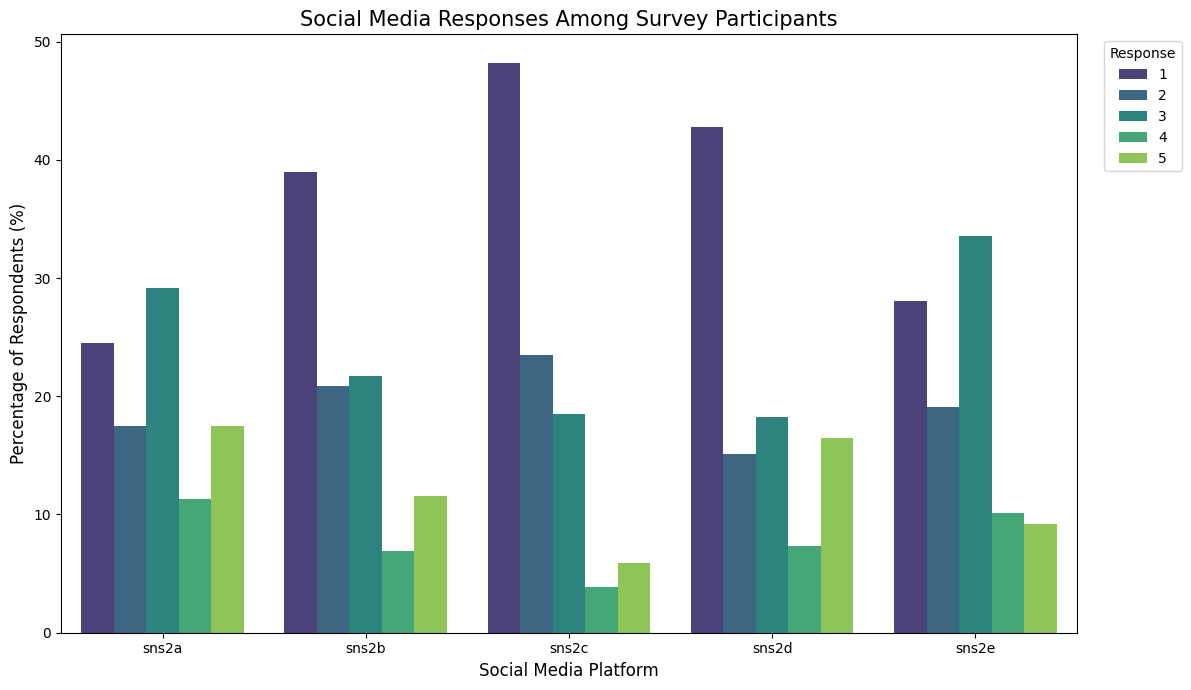

In [ ]:
# [your code here]
#HINTS
# 1) Read your dataframe with pandas
# 2) Identify what colums are used for plot above
# 3) Filter required rows and columns necessary for plotting above figure
# 4) Your dataframe is in wide_format. You need to convert to long_format. See pandas.melt documentation
# i.e. originally there is a column each for these five social medias. The column name should be value for a new column.
# 5) Once dataframe is in wide format, filter individuals who responded to the survey
# 6) Use pandas aggregation after groupby to calculate percentage of responses for each social media
# 7) Use seaborn barplot to plot the figure above. Customize with color palette='viridis'
# 8) Add descriptive xlabel, ylabel, and title
# 9) Customize legend if necessary

# Load dataset
load_survey = pd.read_csv("January 8-February 7, 2019 - Core Trends Survey.csv")

# Print first rows
print(load_survey.columns.tolist())
print(load_survey.head())

# Select the five social media variables
social_media = ["sns2a", "sns2b", "sns2c", "sns2d", "sns2e"]
plot_survey = load_survey[social_media].copy()

# Convert from wide format to long format
long_survey = plot_survey.melt(var_name = "social_media", value_name = "Response")

# Remove missing and blank responses
long_survey["Response"] = long_survey["Response"].astype(str).str.strip()
long_survey = long_survey[(long_survey["Response"] != "") & (long_survey["Response"] != "nan")]

# Remove nonresponse codes
long_survey = long_survey[~long_survey["Response"].isin(["8", "9"])]

# Calculate each response percentage
percent_long_survey = (long_survey.groupby(["social_media", "Response"]).size().reset_index(name = "Count"))
percent_long_survey["Percentage"] = (percent_long_survey.groupby("social_media")["Count"].transform(lambda x: x / x.sum()*100))

# Bar plot
plt.figure(figsize = (12,7))
sns.barplot(data = percent_long_survey, x = "social_media", y = "Percentage", hue = "Response", palette = "viridis")

plt.xlabel("Social Media Platform", fontsize = 12)
plt.ylabel("Percentage of Respondents (%)", fontsize = 12)
plt.title("Social Media Responses Among Survey Participants", fontsize = 15)

plt.legend(
    title="Response",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()



## Q2.1 (10%): Initial exploration

Run descriptive statistics on the data by considering the EDA key data properties we covered in class. Write a 100-150 word description of your findings. Based on these statistics or other ideas you have, form hypotheses that guide your EDA and visualizations for the last three questions. You need to show at least one visualization but you are welcome to show more.

In [ ]:
# Run descriptive statistics on the data and develop ideas on what to explore
# your code here
descriptive_stats = load_survey.describe()
print(descriptive_stats)

              respid       sample    comp       int_date         lang  \
count    1502.000000  1502.000000  1502.0    1502.000000  1502.000000   
mean    95760.697071     1.798935     1.0  190121.531957     1.060586   
std     68225.164352     0.400930     0.0      24.522216     0.238649   
min         4.000000     1.000000     1.0  190108.000000     1.000000   
25%    100130.250000     2.000000     1.0  190110.000000     1.000000   
50%    100719.500000     2.000000     1.0  190114.000000     1.000000   
75%    101327.750000     2.000000     1.0  190118.000000     1.000000   
max    300200.000000     2.000000     1.0  190207.000000     2.000000   

           cregion        state      density         sfips          sex  ...  \
count  1502.000000  1502.000000  1502.000000   1502.000000  1502.000000  ...   
mean      2.663782    27.888149     2.905459  27846.340213     1.448735  ...   
std       1.021817    15.928162     1.385798  15875.274074     0.497531  ...   
min       1.000000    

Dataset dimensions: (1502, 74)

Data types:
int64      37
object     36
float64     1
Name: count, dtype: int64

First five rows:
   respid  sample  comp  int_date  lang  cregion  state  density  sfips usr  \
0       4       1     1    190108     1        3     37        2  37069   S   
1       7       1     1    190108     1        2     39        3  39025   S   
2       9       1     1    190108     1        1     34        4  34025   S   
3      10       1     1    190108     1        2     18        3  18039   S   
4      11       1     1    190114     1        2     26        2  26027   S   

   ... inc  party  partyln  hh1 hh3  ql1  ql1a qc1    weight cellweight  
0  ...   3      2             2   2    1            1.143827             
1  ...   8      1             2   2    1            0.611493             
2  ...   7      1             2   2    1            0.424797             
3  ...   6      3        2    2   2    1            1.323562             
4  ...   7      3        

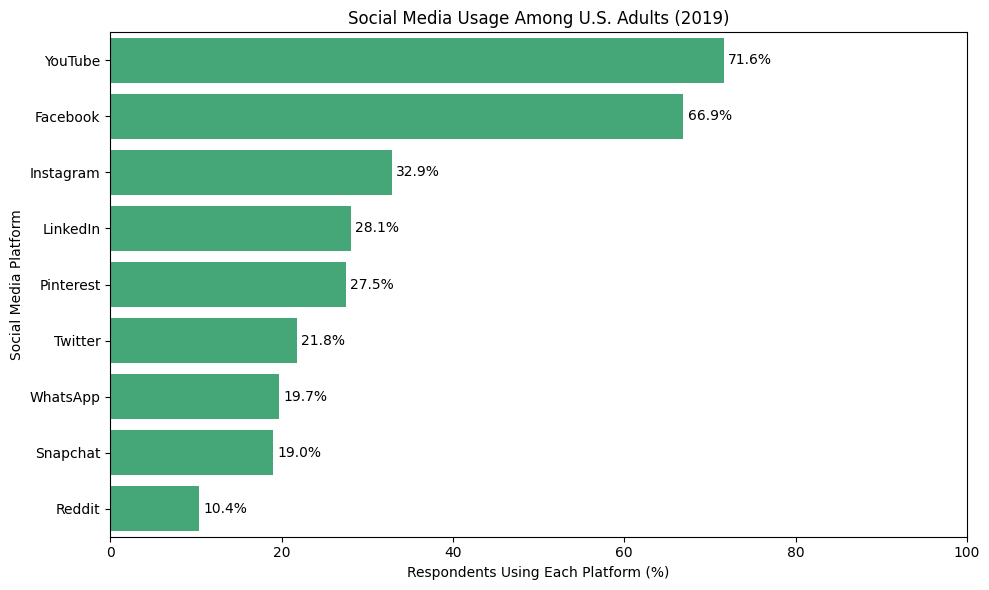

In [ ]:
# Create one or more visualizations
# your code here

print("Dataset dimensions:", load_survey.shape)

print("\nData types:")
print(load_survey.dtypes.value_counts())

print("\nFirst five rows:")
print(load_survey.head())

# Exclude special age codes (98 and 99)
valid_age = load_survey.loc[load_survey["age"] < 98, "age"]

print("\nAge descriptive statistics:")
print(valid_age.describe())

print("\nMissing values by column:")
print(load_survey.isna().sum().sort_values(ascending=False).head(15))

# Count whitespace-only values separately
blank_counts = (
    load_survey.astype(str).apply(lambda col: col.str.strip().eq(""))
    .sum()
)

print("\nColumns with the most blank responses:")
print(blank_counts.sort_values(ascending=False).head(15))

platforms = {
    "web1a": "Twitter",
    "web1b": "Instagram",
    "web1c": "Facebook",
    "web1d": "Snapchat",
    "web1e": "YouTube",
    "web1f": "WhatsApp",
    "web1g": "Pinterest",
    "web1h": "LinkedIn",
    "web1i": "Reddit"
}

long_survey = load_survey[list(platforms)].melt(
    var_name = "Variable",
    value_name = "Response"
)

long_survey["Platform"] = long_survey["Variable"].map(platforms)

# Keep valid responses:
# 1 = Yes; 2 = No
long_survey = long_survey[
    long_survey["Response"].isin([1, 2])
].copy()

# Calculate percentage answering Yes
results = (
    long_survey.assign(Uses = long_survey["Response"].eq(1))
    .groupby("Platform")["Uses"]
    .agg(["mean", "count"])
    .reset_index()
)

results["Percentage"] = results["mean"] * 100

results = results.sort_values(
    "Percentage",
    ascending = False
)

print("\nSocial media usage:")
print(
    results[["Platform", "count", "Percentage"]]
    .round(2)
    .to_string(index = False)
)

# Visualize image
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results,
    x="Percentage",
    y="Platform",
    color=sns.color_palette("viridis", 5)[3]
)

ax.set_xlabel("Respondents Using Each Platform (%)")
ax.set_ylabel("Social Media Platform")
ax.set_title("Social Media Usage Among U.S. Adults (2019)")
ax.set_xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

This visualization calculates the social media usage among U.S. adults in 2019. First, all of the people with no response to social media were deleted. People who were ninety-eight or ninety-nine years old were also excluded. Of the remaining respondants, nine social media platforms in total were used by at least one person from the sample. Based on the graph, Youtube had the highest percentage of respondents at 71.6%, while Reddit had the lowest percentage of respondents at 10.4%. However, if we base the results off of number value, Facebook and Twitter tied for the highest count value at 1502, whereas WhatsApp had the lowest count value at 1486.


## Q2.2 (10%+5%):
### Q2.2.1: Line Chart by Age Group

This line chart compares reported Instagram, Snapchat, Facebook, and YouTube usage across five age groups. Assume age values from 18 to 96 are valid and that responses coded 1 and 2 indicate “Yes” and “No.” Percentages are calculated using valid responses within each age group, without survey weights. Instagram usage declined from 64.4% among respondents aged 18–29 to 7.0% among those aged 75 and older. Snapchat showed a similar pattern, falling from 60.2% to 0.8%. Facebook usage declined less sharply at first, from 78.0% among the youngest group to 39.2% among the oldest. YouTube usage was highest among younger adults but fell to 24.0% in the oldest group. These descriptive patterns support investigating associations between age and platform choice, but they do not establish causation.


Social media usage by age group:
Platform   Facebook  Instagram  LinkedIn  Pinterest  Reddit  Snapchat  Twitter  WhatsApp  YouTube
Age group                                                                                        
18–29          78.0       64.4      28.5       31.8    22.9      60.2     37.7      26.8     90.7
30–44          79.0       50.8      39.7       37.8    17.4      25.3     28.8      37.3     90.5
45–59          70.9       29.1      33.8       28.8     8.4      12.3     22.9      17.9     76.1
60–74          58.1       14.5      20.2       23.8     3.6       3.9     13.2       9.4     58.8
75+            39.2        7.0       6.2        8.6     0.0       0.8      3.1       3.2     24.0


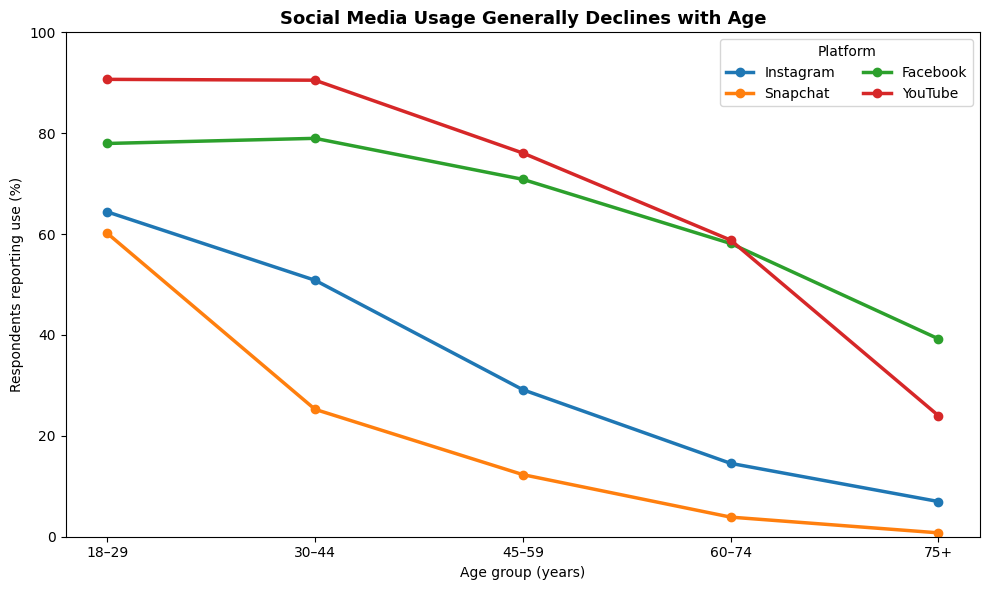

In [ ]:
# your Q2.2.1 visualization code should be included here
# make sure to execute it, so we can see your plot in the submitted pdf
# your code here

# Keep valid ages between 18 and 96
age_df = load_survey.loc[
    load_survey["age"].between(18, 96),
    ["age"] + list(platforms.keys())
].copy()

# Divide respondents into five age groups
age_order = ["18–29", "30–44", "45–59", "60–74", "75+"]

age_df["Age group"] = pd.cut(
    age_df["age"],
    bins=[17, 29, 44, 59, 74, 100],
    labels=age_order
)

# Convert wide data to long format
age_long = age_df.melt(
    id_vars=["age", "Age group"],
    value_vars=list(platforms.keys()),
    var_name="Variable",
    value_name="Response"
)

age_long["Platform"] = age_long["Variable"].map(platforms)

# Keep only valid Yes/No responses
age_long = age_long[
    age_long["Response"].isin([1, 2])
].copy()

# Code Yes as 1 and No as 0
age_long["Uses"] = (
    age_long["Response"] == 1
).astype(int)

# Calculate usage percentages within each age group
age_results = (
    age_long.groupby(
        ["Age group", "Platform"],
        observed=True
    )
    .agg(
        Usage=("Uses", "mean"),
        Valid_responses=("Uses", "count")
    )
    .reset_index()
)

age_results["Percentage"] = age_results["Usage"] * 100

# Display the age-group results
print("\nSocial media usage by age group:")
print(
    age_results.pivot(
        index="Age group",
        columns="Platform",
        values="Percentage"
    ).round(1).to_string()
)

focus_platforms = [
    "Instagram",
    "Snapchat",
    "Facebook",
    "YouTube"
]

focus = age_results[
    age_results["Platform"].isin(focus_platforms)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

for platform in focus_platforms:
    temp = focus[
        focus["Platform"] == platform
    ].copy()

    temp["Age group"] = pd.Categorical(
        temp["Age group"],
        categories=age_order,
        ordered=True
    )

    temp = temp.sort_values("Age group")

    ax.plot(
        temp["Age group"].astype(str),
        temp["Percentage"],
        marker="o",
        linewidth=2.5,
        markersize=6,
        label=platform
    )

ax.set_ylim(0, 100)
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Respondents reporting use (%)")
ax.set_title(
    "Social Media Usage Generally Declines with Age",
    fontsize=13,
    fontweight="bold"
)

ax.legend(title="Platform", ncol=2)

plt.tight_layout()
plt.show()

### Q2.2.2 Alternate visualization

Now use your results and visualization from Q2.2.1 and find an alternate way to visualize it. You are encouraged to look at publicly available examples to guide you and can use any visualization package of your choice. Be creative!

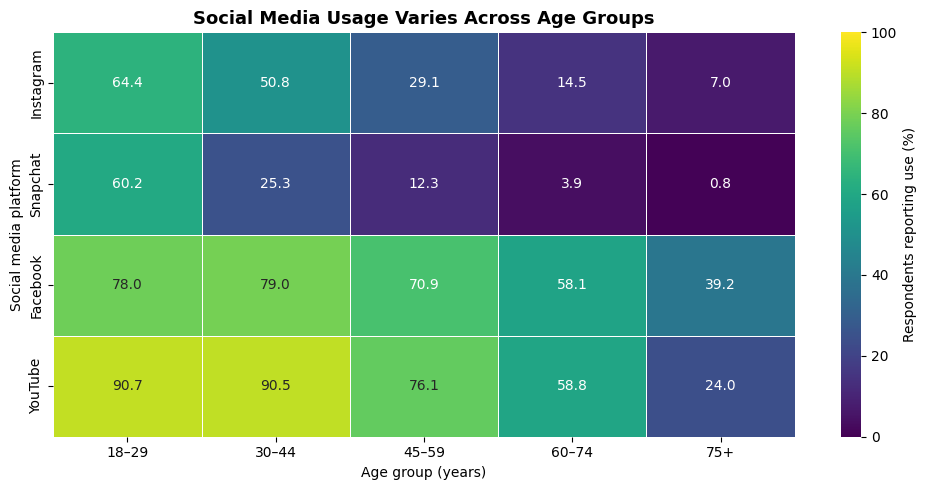

In [ ]:
# your Q2.2.2 visualization code should be included here
heatmap_data = focus.pivot(
    index="Platform",
    columns="Age group",
    values="Percentage"
)

heatmap_data = heatmap_data.reindex(
    index=focus_platforms,
    columns=age_order
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Respondents reporting use (%)"},
    ax=ax
)

ax.set_xlabel("Age group (years)")
ax.set_ylabel("Social media platform")
ax.set_title(
    "Social Media Usage Varies Across Age Groups",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



## Q2.3 (10%+5%):
### Q2.3.1: Comparing Youngest and Oldest Age Groups

The grouped bar chart compares social media usage among respondents aged 18–29 and those aged 75 and older across nine platforms. Assume ages 18–96 are valid and response codes 1 and 2 indicate “Yes” and “No.” Percentages use valid responses within each age group and are unweighted. YouTube, Snapchat, and Instagram show substantial differences between younger and older respondents. The alternative chart displays the size of these differences in percentage points, making it easier to rank platforms by their age gap. This analysis investigates whether platform usage is associated with age, rather than simply ranking overall popularity. However, the findings are descriptive and do not establish causation. The survey's weighting and sample design should be considered before generalizing these results to the entire U.S. adult population.

 Platform  Age 18–29 (%)  Age 75+ (%)  Age gap (percentage points)
 LinkedIn           28.5          6.2                         22.3
   Reddit           22.9          0.0                         22.9
Pinterest           31.8          8.6                         23.2
 WhatsApp           26.8          3.2                         23.6
  Twitter           37.7          3.1                         34.6
 Facebook           78.0         39.2                         38.7
Instagram           64.4          7.0                         57.4
 Snapchat           60.2          0.8                         59.4
  YouTube           90.7         24.0                         66.7


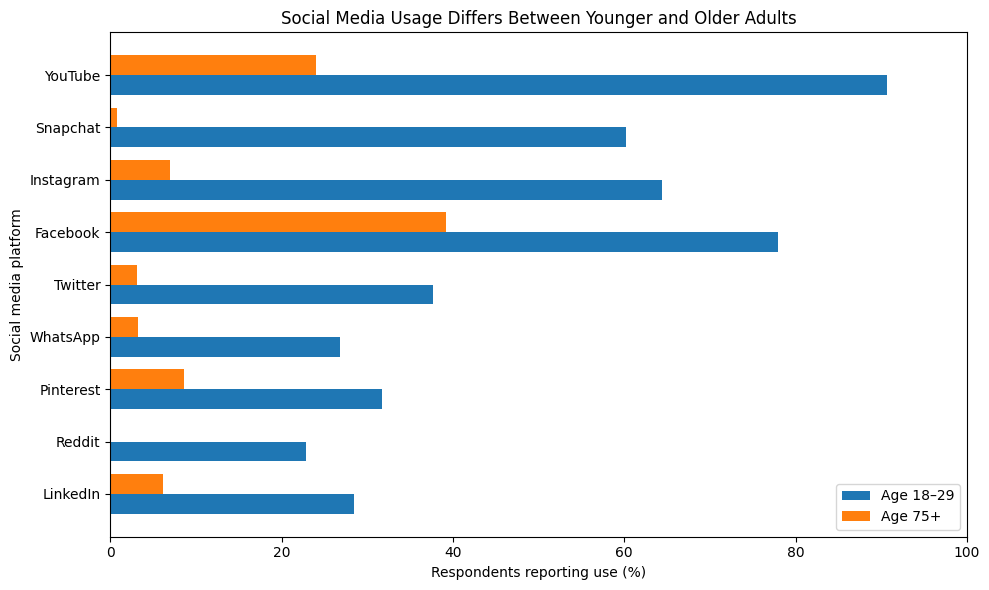

In [ ]:
# your Q2.3.1 visualization code should be included here
# make sure to execute it, so we can see your plot in the submitted pdf
# your code here

# Prepare respondents with valid ages
age_df = load_survey.loc[
    load_survey["age"].between(18, 96),
    ["age"] + list(platforms.keys())
].copy()

age_order = ["18–29", "30–44", "45–59", "60–74", "75+"]

age_df["Age group"] = pd.cut(
    age_df["age"],
    bins=[17, 29, 44, 59, 74, 100],
    labels=age_order
)

# Convert to long format
age_long = age_df.melt(
    id_vars=["age", "Age group"],
    value_vars=list(platforms.keys()),
    var_name="Variable",
    value_name="Response"
)

age_long["Platform"] = age_long["Variable"].map(platforms)

# Keep valid Yes/No responses
age_long = age_long[
    age_long["Response"].isin([1, 2])
].copy()

age_long["Uses"] = (age_long["Response"] == 1).astype(int)

# Calculate usage percentages for each age group
age_results = (
    age_long.groupby(["Age group", "Platform"], observed=True)
    .agg(Usage=("Uses", "mean"))
    .reset_index()
)

age_results["Percentage"] = age_results["Usage"] * 100

# Compare youngest and oldest groups
wide = age_results.pivot(
    index="Platform",
    columns="Age group",
    values="Percentage"
)

comparison = pd.DataFrame({
    "Platform": wide.index,
    "Age 18–29 (%)": wide["18–29"],
    "Age 75+ (%)": wide["75+"]
})

comparison["Age gap (percentage points)"] = (
    comparison["Age 18–29 (%)"] - comparison["Age 75+ (%)"]
)

comparison = comparison.sort_values(
    "Age gap (percentage points)",
    ascending=True
)

print(comparison.round(1).to_string(index=False))

# Primary visualization: grouped horizontal bars
fig, ax = plt.subplots(figsize=(10, 6))

# Bypassing the overwritten 'range' variable using the builtins module
y = __builtins__.range(len(comparison))
height = 0.38

ax.barh(
    [i - height / 2 for i in y],
    comparison["Age 18–29 (%)"],
    height=height,
    label="Age 18–29"
)

ax.barh(
    [i + height / 2 for i in y],
    comparison["Age 75+ (%)"],
    height=height,
    label="Age 75+"
)

ax.set_yticks(list(y))
ax.set_yticklabels(comparison["Platform"])
ax.set_xlim(0, 100)
ax.set_xlabel("Respondents reporting use (%)")
ax.set_ylabel("Social media platform")
ax.set_title(
    "Social Media Usage Differs Between Younger and Older Adults"
)
ax.legend()

plt.tight_layout()
plt.show()

### Q2.3.2 Alternate visualization

Now use your results and visualization from Q2.3.1 and find an alternate way to visualize it. You are encouraged to look at publicly available examples to guide you and can use any visualization package of your choice. Be creative!

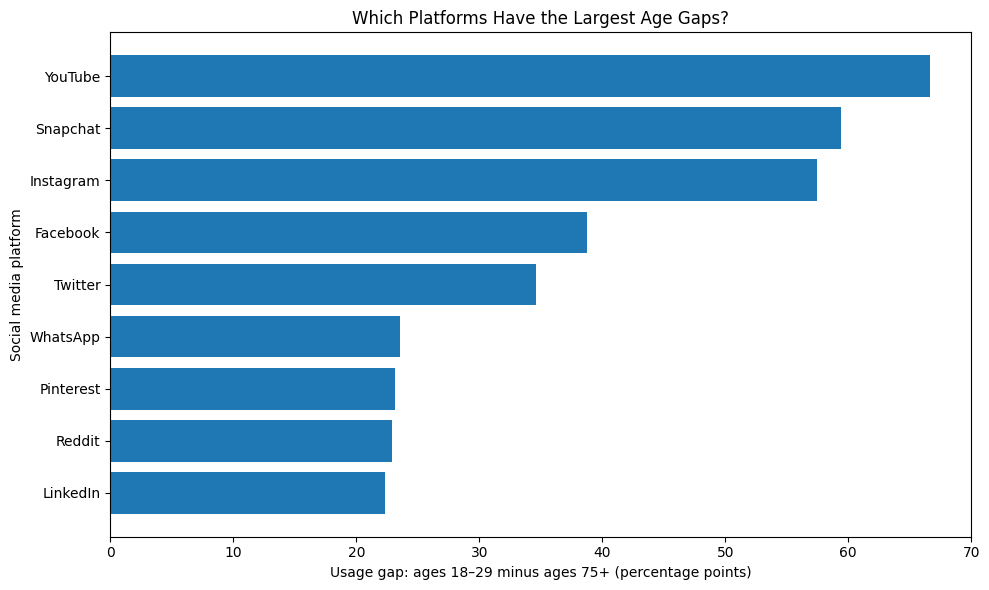

In [ ]:
# your Q2.3.2 visualization code should be included here
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    comparison["Platform"],
    comparison["Age gap (percentage points)"]
)

ax.set_xlabel(
    "Usage gap: ages 18–29 minus ages 75+ (percentage points)"
)
ax.set_ylabel("Social media platform")
ax.set_title("Which Platforms Have the Largest Age Gaps?")

plt.tight_layout()
plt.show()

# Part 3: Error and loss functions (10%)

The last part is about implementing and explore some concepts that we have seen in the class.

## Implement the MSE and MAE
a) Implement MSE (mean Sqaured Error) by your own. Compare with the built-in function (from sklearn.metrics import mean_squared_error) by generating a random sequence of 10 numbers.
b) Implement MAE (mean absolute error) by your own. Compare with the built-in function (from sklearn.metrics import mean_absolute_error) by generating a random sequence of 10 numbers.


In [ ]:
# your code here - MSE
from sklearn.metrics import mean_squared_error

# Generate two random sequences of 10 numbers
np.random.seed(42)
y_true = np.random.rand(10) * 100
y_pred = np.random.rand(10) * 100

# Implement MSE from scratch
def my_mse(y_true, y_pred):
    n = len(y_true)
    squared_errors = (y_true - y_pred) ** 2
    return np.sum(squared_errors) / n

# Calculate MSE using both methods
mse_custom = my_mse(y_true, y_pred)
mse_sklearn = mean_squared_error(y_true, y_pred)

# Display results
print("Actual values:", y_true)
print("Predicted values:", y_pred)
print("MSE (my implementation):", mse_custom)
print("MSE (sklearn):", mse_sklearn)
print("Results match:", np.isclose(mse_custom, mse_sklearn))

Actual values: [37.45401188 95.07143064 73.19939418 59.86584842 15.60186404 15.59945203
  5.80836122 86.61761458 60.11150117 70.80725778]
Predicted values: [ 2.05844943 96.99098522 83.24426408 21.23391107 18.18249672 18.34045099
 30.4242243  52.47564316 43.19450186 29.12291402]
MSE (my implementation): 665.9413573920301
MSE (sklearn): 665.9413573920301
Results match: True


In [ ]:
# your code here - MAE
from sklearn.metrics import mean_absolute_error

# Implement MAE from scratch
def my_mae(y_true, y_pred):
    n = len(y_true)
    absolute_errors = np.abs(y_true - y_pred)
    return np.sum(absolute_errors) / n

# Calculate MAE using both methods
mae_custom = my_mae(y_true, y_pred)
mae_sklearn = mean_absolute_error(y_true, y_pred)

# Display results
print("Actual values:", y_true)
print("Predicted values:", y_pred)
print("MAE (my implementation):", mae_custom)
print("MAE (sklearn):", mae_sklearn)
print("Results match:", np.isclose(mae_custom, mae_sklearn))

Actual values: [37.45401188 95.07143064 73.19939418 59.86584842 15.60186404 15.59945203
  5.80836122 86.61761458 60.11150117 70.80725778]
Predicted values: [ 2.05844943 96.99098522 83.24426408 21.23391107 18.18249672 18.34045099
 30.4242243  52.47564316 43.19450186 29.12291402]
MAE (my implementation): 20.867273347264426
MAE (sklearn): 20.867273347264426
Results match: True


# Extra Credit (10%)
Explain what the Huber loss is and how it differs from traditional loss functions like Mean Squared Error (MSE). What role does the parameter
 δ play in the Huber loss function? Provide an example scenario where using Huber loss might be beneficial compared to using MSE.

The Huber loss is a robust regression loss function that is quadratic for small errors and linear for large errors. Unlike MAE and MSE, the Huber loss blends the strengths of both MAE and MSE by changing its pattern based on the residuals. The parameter delta helps the function become less sensitive to outliers than MAE and MSE.

For example, imagine a machine-learning model being used to predict house prices. Most houses in this dataset have prices between $200,000 and $600,000, but one house is incorrectly recorded as $10 million.

With MSE, the error associated with the house is squared which influences the model greatly. It is possible that the model may adjust its parameters significantly just to reduce the error for this one observation. With the Huber loss, once the error exceeds the delta parameter, the penalty grows linearly instead of quadratically. As a result, the $10 million outlier still contributes to the loss, but it does not dominate the model.

This was the last part of Homework 2. Now you need to submit your work following the instructions in the beginning of the notebook and you are done!